In [1]:
import sys
sys.path.append('../data')
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget
from sklearn.datasets import make_blobs
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
np.set_printoptions(precision=2)
from lab_utils_multiclass_TF import *
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

In [2]:
classes = 4
std = 1.0
centers = [[-5, 2], [-2, -2], [1, 2], [5, -2]]
m = 100
X_train,Y_train = make_blobs(n_samples=m , centers= centers , cluster_std= std , random_state= 30 )

/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,


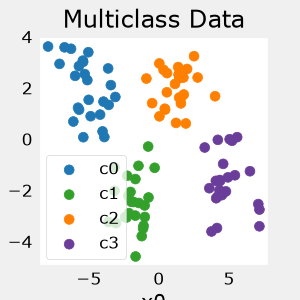

In [3]:
plt_mc(X_train,Y_train,classes,centers,std=std)

In [4]:
print(f"Unique classes :  {np.unique(Y_train)}")
print(f"Class Representation :  {Y_train [:10]}")
print(f"shape of X_train : {X_train.shape} , shape of Y_train : {Y_train.shape}")

Unique classes :  [0 1 2 3]
Class Representation :  [3 3 3 0 3 3 3 3 2 0]
shape of X_train : (100, 2) , shape of Y_train : (100,)


In [5]:
tf.random.set_seed(1234)
model = Sequential(
    [
        Dense(2,activation='relu', name = "L1"),
        Dense(4,activation='linear', name = "L2")
    ]
)

In [6]:
model.compile(
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer = tf.keras.optimizers.Adam(0.01)
)

In [7]:
model.fit(
    X_train,Y_train,
    epochs = 200
    )


Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.5681  
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.3070 
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0968 
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.9232 
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.7790 
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6610 
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5650 
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4855 
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.4174 
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3569 
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3040 
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2531 
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2047 
Epoch 14/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.1593 
Epoch 15/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.1158 
Epoch 16/200
4/4 ━

184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step


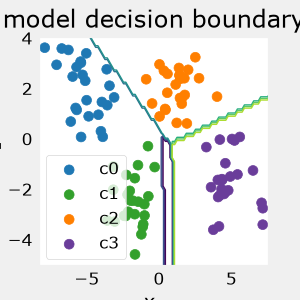

In [8]:
plt_cat_mc(X_train,Y_train,model,classes)

In [9]:
l1 = model.get_layer("L1")
W1,b1 = l1.get_weights()
print(f"W1 : {W1}")
print("b1 : {b1}")

W1 : [[1.49 1.66]
 [1.99 0.04]]
b1 : {b1}


/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,


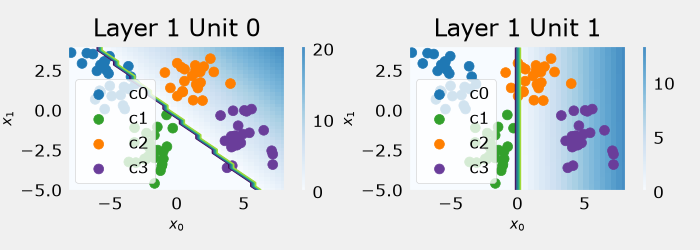

In [10]:
plt_layer_relu(X_train,Y_train.reshape(-1,) , W1,b1,classes)

In [11]:
l2 = model.get_layer("L2")
W2,b2 = l2.get_weights()
print(f"W2 : {W2}")
print("b2 : {b2}")

W2 : [[-0.52 -0.49  1.6  -0.25]
 [-0.49 -1.16 -0.61  1.65]]
b2 : {b2}


/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
/Users/Sreesanth/ML/C2/../data/lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,


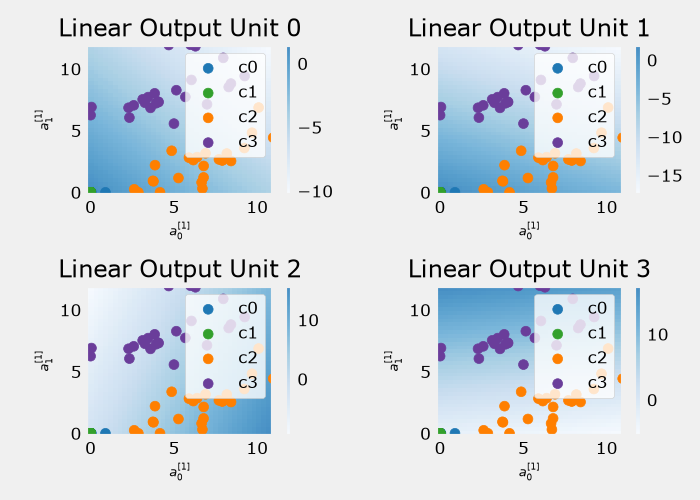

In [12]:
Xl2 = np.maximum(0 , np.dot(X_train,W1) + b1)
plt_output_layer_linear(Xl2,Y_train.reshape(-1,),W2,b2,classes,x0_rng=(-0.25,np.amax(Xl2[:,0])),x1_rng=(-0.25,np.amax(Xl2[:,1])))